# Wandb group comparison

Groups of residual runs compared on wandb: each group is one condition, each `<group>_a<k>` run one agent, and each
`<group>_a<k>_eval` run that agent's evaluations (one per checkpoint, `eval/success_rate` and `eval/length_mean` at the
training step it was taken).

Cells: 1 imports, 2 variables, 3 download (every run of the project carrying `TAG`, cached in `data_analysis/cache/`),
4 processing, then one plot per cell. The success rate and length bars use each agent's best checkpoint (its highest
`eval/success_rate` from step `MIN_BEST_STEP` on), and the base policy's bar every eval run's base round (step 0); the bars are the mean over agents and the error bars the 95% confidence interval of that mean
(Student t, n - 1 degrees of freedom). Figures are saved to `SAVE_DIR` as `{plot}_{tag}.{png,svg}`.

In [43]:
import pickle
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wandb
from scipy import stats

# the repo root, for the cache and figure folders
REPO = Path.cwd().resolve()
while not (REPO / "my_project").is_dir():
    if REPO.parent == REPO:
        raise RuntimeError("run this notebook from inside the hybrid_demos repo")
    REPO = REPO.parent

In [ ]:
# the runs: every run of ENTITY/PROJECT carrying TAG
ENTITY = "hur"
PROJECT = "residual_noise_compare"
TAG = "square"


# each group's colour, in plot order; groups not listed come after, in name order, with spare colours
GROUP_COLOURS = {
    f"noise_{TAG}_resfit": "#1f77b4",
    f"noise_{TAG}_scaled_fixed": "#ff7f0e",
    #"noise_square_scaled_linfit": "#2ca02c",
    f"noise_{TAG}_add_mlp": "#d62728",
    f"noise_{TAG}_add_linfit": "#9467bd",
    #"noise_square_add_lin005": "#8c564b",
    f"noise_{TAG}_add_linfit_resfitwarm": "#1aff00",
}
# True: only the groups in GROUP_COLOURS are plotted; False: every group with the tag
ONLY_COLOURED = True
# each group's display name, used for every label (a plotted group missing here is refused)
GROUP_NAMES = {
    f"noise_{TAG}_resfit": "ResFiT",
    f"noise_{TAG}_scaled_fixed": "Scaled fixed",
    "noise_square_scaled_linfit": "Scaled linfit",
    f"noise_{TAG}_add_mlp": "Additive MLP",
    f"noise_{TAG}_add_linfit": "Additive linfit",
    "noise_square_add_lin005": "Additive lin 0.05",
    f"noise_{TAG}_add_linfit_resfitwarm": "Additive linfit, ResFiT warm-up",
}

# the base policy's bar, first: the base round (the eval at training step 0, before any update) of every eval run with
# the tag, one value per run; False leaves it out
BASE_BAR = True
BASE_NAME = "Base policy"
BASE_COLOUR = "#7f7f7f"

# the agents' run names: <group>_a<k> trains, <group>_a<k>_eval evaluates (other runs in a group, e.g. a smoke test,
# are ignored)
AGENT_RUN = r"^(?P<group>.+)_a(?P<agent>\d+)$"
EVAL_RUN = r"^(?P<group>.+)_a(?P<agent>\d+)_eval$"

# the eval metrics
SUCCESS_KEY = "eval/success_rate"
LENGTH_KEY = "eval/length_mean"
# the first checkpoint a best may come from: the earlier ones are the base policy (no update before 10k steps) or barely
# trained. The checkpoint after 20k steps is logged at step 19999
MIN_BEST_STEP = 19999
# the length bars: "best_success" the length at each agent's best success checkpoint (the same checkpoint as the
# success bars), "min" each agent's shortest mean length over its checkpoints
LENGTH_AT = "best_success"

# the training metrics of the line plot: (key, panel title, y label)
RESIDUAL_PANELS = [
    ("residual/position_mm", "Position", "average residual correction (mm)"),
    ("residual/rot_deg", "Rotation", "average residual correction (deg)"),
]

# the confidence level of every interval
CI = 0.95

# download once; True re-downloads (a group's runs changed or finished)
REFRESH = False
# the most rows downloaded per run and metric set (wandb returns every row below it; a run reaching it is refused)
HISTORY_SAMPLES = 100000
CACHE_DIR = REPO / "data_analysis" / "cache" / "wandb_groups"

# where the figures go, and as what
SAVE_DIR = REPO / "data_analysis" / "wandb_plots" / PROJECT
SAVE_FORMATS = ["png", "svg"]
DPI = 150
FONT_SIZE = 11
plt.rcParams.update({"font.size": FONT_SIZE})

In [45]:
cache = Path(CACHE_DIR) / f"{ENTITY}_{PROJECT}_{TAG}.pkl"
if cache.is_file() and not REFRESH:
    with open(cache, "rb") as f:
        raw = pickle.load(f)
    print(f"loaded {cache} (downloaded {raw['downloaded']}); REFRESH = True to download again")
else:
    def history(run, keys):
        """Every logged row of ``keys``: run.history is one request (scan_history pages for a minute a run), and it
        returns every row while a run has fewer than HISTORY_SAMPLES of them -- refused when it may have thinned them."""
        frame = run.history(keys=keys, samples=HISTORY_SAMPLES, pandas=True)
        if len(frame) >= HISTORY_SAMPLES:
            raise ValueError(f"{run.name}: {len(frame)} rows reach HISTORY_SAMPLES ({HISTORY_SAMPLES}), so wandb may have "
                             "sampled them: raise HISTORY_SAMPLES")
        return frame.to_dict("records")

    api = wandb.Api(timeout=120)
    runs = api.runs(f"{ENTITY}/{PROJECT}", filters={"tags": {"$in": [TAG]}})
    evals, trains, ignored = [], [], []
    residual_keys = [key for key, _, _ in RESIDUAL_PANELS]
    for run in runs:
        if (m := re.match(EVAL_RUN, run.name)) and m["group"] == run.group:
            rows = history(run, [SUCCESS_KEY, LENGTH_KEY])
            evals += [{"group": run.group, "agent": int(m["agent"]), "run": run.name, "state": run.state, **r} for r in rows]
        elif (m := re.match(AGENT_RUN, run.name)) and m["group"] == run.group:
            rows = history(run, residual_keys)
            trains += [{"group": run.group, "agent": int(m["agent"]), "run": run.name, "state": run.state, **r} for r in rows]
        else:
            ignored.append(run.name)
        print(f"{run.name} ({run.state})", flush=True)
    raw = {"evals": pd.DataFrame(evals), "trains": pd.DataFrame(trains), "ignored": ignored,
           "downloaded": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")}
    cache.parent.mkdir(parents=True, exist_ok=True)
    with open(cache, "wb") as f:
        pickle.dump(raw, f)
evals, trains = raw["evals"], raw["trains"]
if evals.empty:
    raise ValueError(f"{ENTITY}/{PROJECT}: no eval runs ({EVAL_RUN}) carry the tag {TAG!r}")
print(f"{evals['run'].nunique()} eval runs, {trains['run'].nunique()} training runs; ignored {raw['ignored']}")
unfinished = sorted(set(evals.loc[evals["state"] != "finished", "run"]) | set(trains.loc[trains["state"] != "finished", "run"]))
if unfinished:
    print(f"note: not finished when downloaded: {unfinished}")

loaded /home/hunter/hybrid_demos/data_analysis/cache/wandb_groups/hur_residual_noise_compare_can.pkl (downloaded 2026-11-19 13:06); REFRESH = True to download again
18 eval runs, 18 training runs; ignored ['noise_can_resfit_a0_smoke_test']


In [46]:
# the groups plotted, in order: GROUP_COLOURS's, then the rest by name
found = sorted(set(evals["group"]) | set(trains["group"]))
missing = [g for g in GROUP_COLOURS if g not in found]
if missing:
    print(f"note: GROUP_COLOURS names groups with no {TAG!r} runs: {missing}")
groups = [g for g in GROUP_COLOURS if g in found] + ([] if ONLY_COLOURED else [g for g in found if g not in GROUP_COLOURS])
_spare = iter(c for c in plt.get_cmap("tab10").colors + plt.get_cmap("Dark2").colors if c not in GROUP_COLOURS.values())
colours = {g: GROUP_COLOURS.get(g) or next(_spare) for g in groups}
unnamed = [g for g in groups if g not in GROUP_NAMES]
if unnamed:
    raise KeyError(f"GROUP_NAMES has no display name for the plotted groups {unnamed}")
labels = {g: GROUP_NAMES[g] for g in groups}


def mean_ci(values):
    """The mean of the values and the half-width of its CI confidence interval (Student t); nan for one value."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    n = len(values)
    if n < 2:
        return (values.mean() if n else np.nan), np.nan, n
    return values.mean(), stats.t.ppf(0.5 + CI / 2, n - 1) * values.std(ddof=1) / np.sqrt(n), n


# each agent's best checkpoint: its highest success rate (the earliest step on a tie)
checkpoints = evals[evals["group"].isin(groups)].dropna(subset=[SUCCESS_KEY])
checkpoints = checkpoints[checkpoints["_step"] >= MIN_BEST_STEP]
best = (checkpoints.sort_values(["group", "agent", SUCCESS_KEY, "_step"], ascending=[True, True, False, True])
        .groupby(["group", "agent"]).head(1).set_index(["group", "agent"]))
if LENGTH_AT not in ("best_success", "min"):
    raise ValueError(f"LENGTH_AT {LENGTH_AT!r}: best_success or min")
best["length"] = (best[LENGTH_KEY] if LENGTH_AT == "best_success"
                  else checkpoints.groupby(["group", "agent"])[LENGTH_KEY].min())

def summary_row(g):
    agents = best.loc[g]
    success, success_half, n = mean_ci(agents[SUCCESS_KEY])
    length, length_half, _ = mean_ci(agents["length"])
    return {"agents": n, "best success (each)": " ".join(f"{v:.2f}" for v in agents[SUCCESS_KEY]),
            "at step": " ".join(str(int(s)) for s in agents["_step"]), "success": success,
            f"success ±{CI:.0%} CI": success_half, "length": length, f"length ±{CI:.0%} CI": length_half}


no_evals = [g for g in groups if g not in best.index.get_level_values(0)]
if no_evals:
    raise ValueError(f"no {SUCCESS_KEY} checkpoints for the groups {no_evals}: their _a<k>_eval runs are missing")
# the base policy: every eval run's base round (step 0), whatever its group
base_round = evals[evals["_step"] == 0].dropna(subset=[SUCCESS_KEY]).set_index(["group", "agent"])
base_round["length"] = base_round[LENGTH_KEY]
if BASE_BAR:
    no_base = sorted(set(evals["run"]) - set(evals.loc[evals["_step"] == 0, "run"]))
    if no_base:
        raise ValueError(f"the eval runs {no_base} have no base round (step 0) for the base policy's bar")

# the bars, in order: (label, colour, one row per value with SUCCESS_KEY and "length")
bar_groups = ([(BASE_NAME, BASE_COLOUR, base_round)] if BASE_BAR else []) + [(labels[g], colours[g], best.loc[g]) for g in groups]

summary = pd.DataFrame({labels[g]: summary_row(g) for g in groups}).T
if BASE_BAR:
    success, success_half, n = mean_ci(base_round[SUCCESS_KEY])
    length, length_half, _ = mean_ci(base_round["length"])
    summary = pd.concat([pd.DataFrame({BASE_NAME: {"agents": n, "best success (each)": "", "at step": "0 (every run)",
                                                   "success": success, f"success ±{CI:.0%} CI": success_half,
                                                   "length": length, f"length ±{CI:.0%} CI": length_half}}).T, summary])
display(summary)

# the training curves: every agent's value at every logged step, as a (step x agent) table per group and metric
curves = {(g, key): trains[trains["group"] == g].pivot_table(index="_step", columns="agent", values=key)
          for g in groups for key, _, _ in RESIDUAL_PANELS if key in trains}

SAVE_DIR = Path(SAVE_DIR)
SAVE_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, plot):
    for fmt in SAVE_FORMATS:
        fig.savefig(SAVE_DIR / f"{plot}_{TAG}.{fmt}", dpi=DPI, bbox_inches="tight")

note: GROUP_COLOURS names groups with no 'can' runs: ['noise_can_add_linfit_resfitwarm']


,agents,best success (each),at step,success,success ±95% CI,length,length ±95% CI
Base policy,18,,0 (every run),0.8,0.0,160.716665,0.012062
ResFiT,3,1.00 0.98 0.97,139999 139999 159999,0.983333,0.037946,107.773331,5.425459
Scaled fixed,3,1.00 0.98 0.98,189999 199999 199999,0.986667,0.028684,97.063332,12.700338
Additive MLP,3,0.98 0.98 0.97,119999 179999 189999,0.976667,0.014342,114.859998,4.175348
Additive linfit,3,0.98 0.96 0.97,119999 89999 169999,0.97,0.024841,116.709997,6.749315


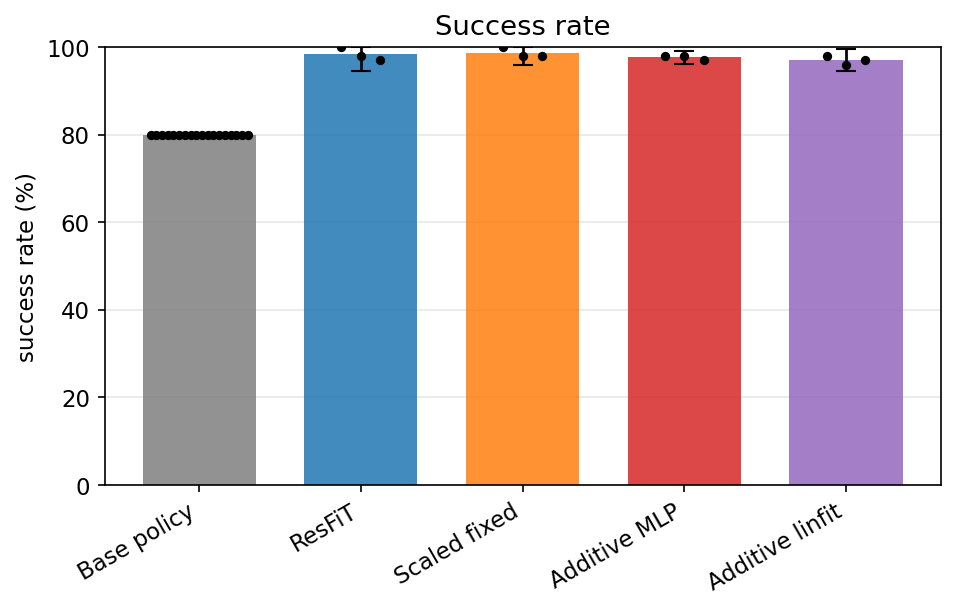

In [47]:
def bar_plot(column, title, ylabel, scale=1.0, ylim=(0, None), plot=None):
    """One bar per entry of ``bar_groups`` (the base policy's base rounds, then each group's agents at their best
    checkpoint): the mean of ``column``, CI error bars (cut at the axis limits ``ylim``: no negative length or success
    rate, none above 100%), each value as a dot."""
    fig, ax = plt.subplots(figsize=(max(4.0, 1.0 * len(bar_groups) + 1.5), 4.2), dpi=DPI)
    for x, (_, colour, rows) in enumerate(bar_groups):
        values = rows[column].to_numpy() * scale
        mean, half, n = mean_ci(values)
        ax.bar(x, mean, color=colour, alpha=0.85, width=0.7)
        if not np.isnan(half):
            low = max(mean - half, ylim[0]) if ylim[0] is not None else mean - half
            high = min(mean + half, ylim[1]) if ylim[1] is not None else mean + half
            ax.errorbar(x, mean, yerr=[[mean - low], [high - mean]], color="black", capsize=5, lw=1.3)
        spread = min(0.3, 0.04 * n)
        ax.scatter(x + np.linspace(-spread, spread, n), values, color="black", s=12, zorder=3)
    ax.set_xticks(range(len(bar_groups)), [label for label, _, _ in bar_groups], rotation=30, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save(fig, plot)
    plt.show()


bar_plot(SUCCESS_KEY, "Success rate", "success rate (%)", scale=100.0, ylim=(0, 100), plot="success_rate")

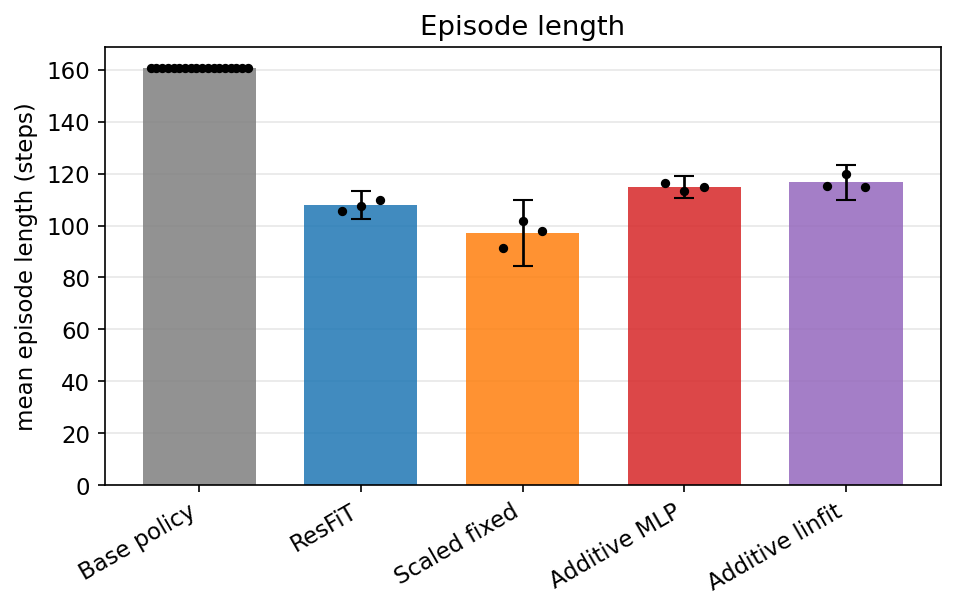

In [48]:
bar_plot("length", "Episode length", "mean episode length (steps)", plot="length_mean")

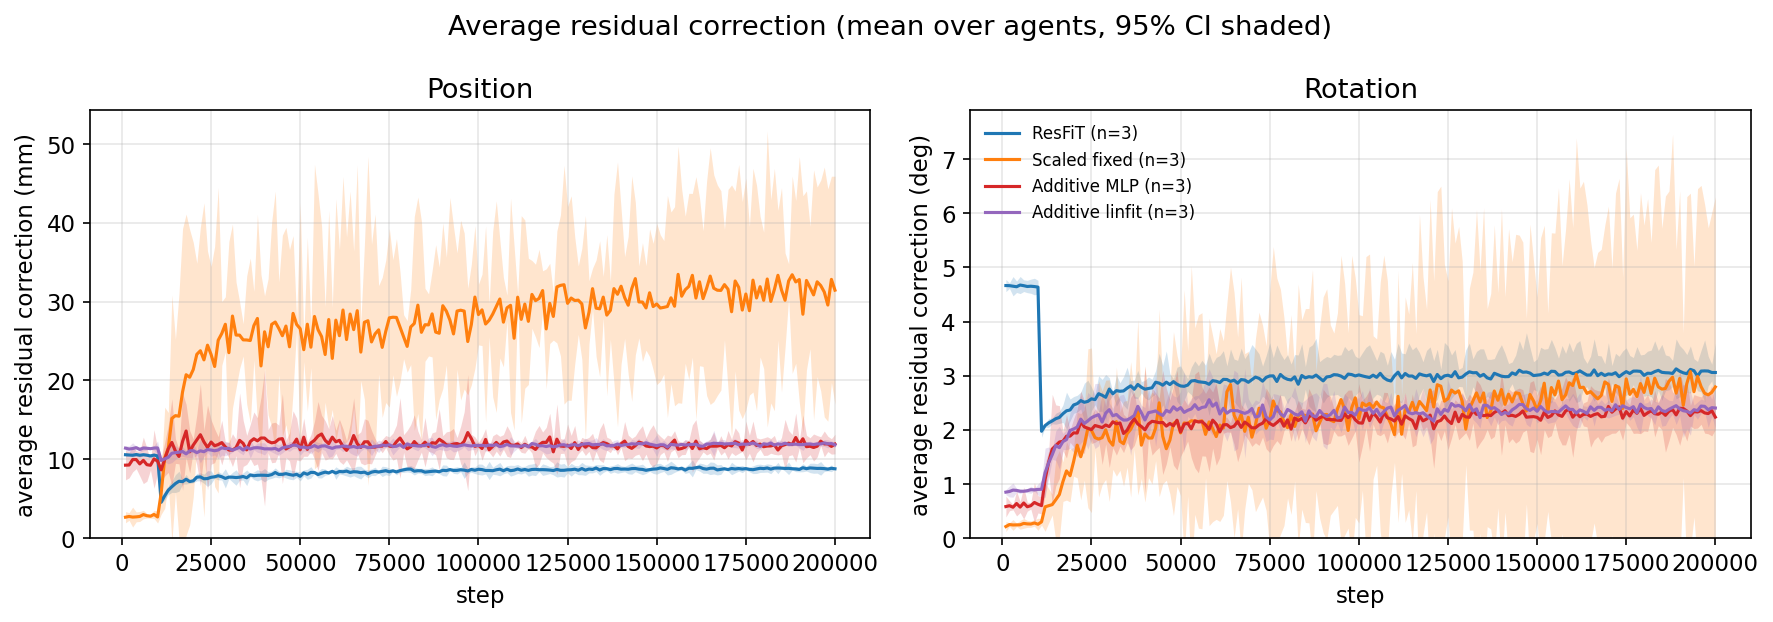

In [49]:
fig, axes = plt.subplots(1, len(RESIDUAL_PANELS), figsize=(6.0 * len(RESIDUAL_PANELS), 4.2), dpi=DPI, squeeze=False)
for ax, (key, title, ylabel) in zip(axes[0], RESIDUAL_PANELS):
    for g in groups:
        table = curves.get((g, key))
        if table is None or table.empty:
            continue
        stat = table.apply(lambda row: pd.Series(mean_ci(row.to_numpy()), index=["mean", "half", "n"]), axis=1)
        steps = stat.index.to_numpy()
        ax.plot(steps, stat["mean"], color=colours[g], lw=1.5, label=f"{labels[g]} (n={int(stat['n'].max())})")
        ax.fill_between(steps, stat["mean"] - stat["half"], stat["mean"] + stat["half"], color=colours[g], alpha=0.2,
                        lw=0)
    ax.set_xlabel("step")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0, -1].legend(fontsize=8, frameon=False, loc="best")
fig.suptitle(f"Average residual correction (mean over agents, {CI:.0%} CI shaded)")
fig.tight_layout()
save(fig, "residual_correction")
plt.show()